# Metro overlay: do persistent H1 loops trace Medellín's transit corridors?

**Input:** a zigzag persistence diagram (H0/H1 bars) produced by
`eod_zigzag_persistence.ipynb`, as a CSV with columns
`dim, birth_min, death_min, birth_h, death_h, persistence_h`.

**Question:** an H1 bar is a cycle of mutual trip exchange between ≥4 zones. Are the
zones that make up the *longest-lived* such cycles located near Medellín's Metro /
Metrocable / Tranvía lines, more than a same-size random group of zones would be, or
is their location indistinguishable from chance?

**Why a persistence diagram alone can't answer this.** The diagram records *when*
each loop is born and dies (window index and duration) but not *which* zones form
it — that geographic identity was thrown away by the zigzag computation itself, which
only tracks homology classes, not their representative cycles. To recover "which
zones", this notebook re-derives snapshot graphs from the original survey trips at
the CSV's own window centers and asks, for each selected bar, which chordless cycle
of zones is common to every window the bar spans — the same procedure
`eod_zigzag_persistence.ipynb` uses for its own Figure 5, generalized here to run on
an arbitrary bar list.

**The naive test doesn't work.** Asking "does the loop's connecting polygon cross a
transit line" is dominated by geometry, not signal: because the rail lines run the
length of the dense valley center where loop density is also highest, random
same-size zone loops cross the network 95–99% of the time regardless of any real
association. This notebook instead measures, per cycle, the mean distance from its
**zone centroids** (not the connecting polygon) to the nearest transit line, and
compares that against a null of random same-size zone tuples drawn from the same
pool of "ever active" zones the real cycles are drawn from.

**What this notebook does *not* rule out.** The null here is spatially random, not
degree-preserving. If transit runs through the highest-degree zones (the ones with
the most trip connections), a positive result could reflect that degree confound
rather than anything specific to transit. See the companion `null_models.py` for a
degree-preserving null on barcode structure; extending that null to cycle *identity*
is future work, not done here.

## 1. Parameters

Edit this cell and re-run the notebook to explore a different barcode, population size, or windowing configuration.

In [3]:
from pathlib import Path

# --- the two user inputs -----------------------------------------------------
# 1. Any zigzag persistence diagram with columns dim, birth_min, death_min,
#    birth_h, death_h, persistence_h -- e.g. outputs/zigzag_bars.csv, or a barcode
#    from a different window/threshold configuration produced by run_pipeline()
#    in eod_zigzag_persistence.ipynb.
BARCODE_CSV = Path("outputs/zigzag_bars.csv")

# 2. How many EXTRA shorter-lived H1 bars to add to the analysis population,
#    beyond the "core" long-lived bars (persistence_h > LONG_LIVED_H_MIN). Set to
#    0 to analyze only the core; raise it to see whether the transit association
#    weakens as shorter-lived, less distinctive loops are folded in.
N_EXTRA_SHORT_LIVED = 15

# --- population definition ---------------------------------------------------
LONG_LIVED_H_MIN = 4.0   # hours; matches the cutoff used in publication_assessment.md

# --- windowing / edge-support config ------------------------------------------
# Must match whatever configuration produced BARCODE_CSV, so the reconstructed
# snapshot graphs land on the same window centers as the bars' birth_min/death_min.
# Defaults match eod_zigzag_persistence.ipynb's own defaults.
WINDOW_MIN = 60
OVERLAP    = 0.5
DAY_MIN    = 1440
MIN_TRIPS  = 100
TRIP_COUNT = "expanded"

# --- data paths ----------------------------------------------------------------
DATA_DIR    = Path("data")
TRIPS_XLSX  = DATA_DIR / "AMVA_EOD_viajes_2017.xlsx"
ZONES_SHP   = DATA_DIR / "EOD_2017_polygons_all.shp"
TRANSIT_SHP = DATA_DIR / "transit" / "transit_lines_2017.shp"
OUT_DIR     = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
SHEET  = "EOD_viajes_2017"
FE_COL = "fe_estratos_sin a pie 1 y 2"

# --- cycle extraction ----------------------------------------------------------
MAX_CYCLE_LEN = 6   # matches the notebook's own indicative_h1_cycles default
TOPK_PER_BAR  = 2   # indicative cycles kept per bar (some bars admit several)
TOP_K_SHOWN   = 5   # distinct cycles drawn on the map (largest-persistence first)

# --- null model ------------------------------------------------------------------
SEED = 20170101
N_NULL_DRAWS  = 3000   # per-cycle null draws, for the percentile-rank table
N_PERMUTE     = 2000   # replicates for the aggregate permutation p-value

assert BARCODE_CSV.exists(), f"barcode CSV not found at {BARCODE_CSV.resolve()}"
assert TRIPS_XLSX.exists(), f"trip workbook not found at {TRIPS_XLSX.resolve()}"
assert ZONES_SHP.exists(), f"zone shapefile not found at {ZONES_SHP.resolve()}"
assert N_EXTRA_SHORT_LIVED >= 0
STEP_MIN = int(WINDOW_MIN * (1 - OVERLAP))
print(f"barcode: {BARCODE_CSV}")
print(f"population: core (>{LONG_LIVED_H_MIN}h) + {N_EXTRA_SHORT_LIVED} extra shorter-lived bars")
print(f"window {WINDOW_MIN} min, step {STEP_MIN} min -> {len(range(0, DAY_MIN, STEP_MIN))} snapshots")

barcode: outputs/zigzag_bars.csv
population: core (>4.0h) + 15 extra shorter-lived bars
window 60 min, step 30 min -> 48 snapshots


## 2. Load the barcode and select the analysis population

The population is the **core**: every H1 bar with `persistence_h > LONG_LIVED_H_MIN`,
plus the `N_EXTRA_SHORT_LIVED` next-longest-lived H1 bars below that cutoff. This lets
you check whether a transit association found in the core survives, strengthens, or
dilutes as shorter-lived (less distinctive) loops are added.

In [5]:
import pandas as pd

raw_bars = pd.read_csv(BARCODE_CSV)
required_cols = {"dim", "birth_min", "death_min", "birth_h", "death_h", "persistence_h"}
missing = required_cols - set(raw_bars.columns)
assert not missing, f"barcode CSV is missing columns: {missing}"

h1 = raw_bars[raw_bars.dim == 1].sort_values("persistence_h", ascending=False).reset_index(drop=True)
core = h1[h1.persistence_h > LONG_LIVED_H_MIN]
rest = h1[h1.persistence_h <= LONG_LIVED_H_MIN]
extra = rest.head(N_EXTRA_SHORT_LIVED)
population = pd.concat([core, extra]).reset_index(drop=True)

print(f"H1 bars in barcode: {len(h1)}")
print(f"core (persistence_h > {LONG_LIVED_H_MIN}h): {len(core)}")
print(f"extra shorter-lived bars added: {len(extra)} (requested {N_EXTRA_SHORT_LIVED})")
print(f"analysis population: {len(population)} bars")
print(population[["birth_h", "death_h", "persistence_h"]].describe().to_string())

H1 bars in barcode: 10569
core (persistence_h > 4.0h): 48
extra shorter-lived bars added: 15 (requested 15)
analysis population: 63 bars
         birth_h    death_h  persistence_h
count  63.000000  63.000000      63.000000
mean   11.666667  16.063492       4.396825
std     2.982138   2.956666       0.489064
min     4.750000   9.000000       3.750000
25%     9.750000  14.000000       4.250000
50%    11.750000  16.500000       4.250000
75%    13.750000  18.000000       4.750000
max    16.750000  21.000000       5.750000


## 3. Rebuild snapshot graphs from the original survey

The persistence diagram has no zone membership, so the snapshot graphs the bars were
computed from are rebuilt here from the raw AMVA trip data, using the same
window/threshold rule as `eod_zigzag_persistence.ipynb` (`window_edges`): an edge
enters a snapshot when its activity interval intersects the window and its trips
clear `MIN_TRIPS`.

In [7]:
import numpy as np

raw = pd.read_excel(TRIPS_XLSX, sheet_name=SHEET,
                     usecols=["sit_o", "sit_d", "hora_o", "hora_d", FE_COL])

def to_minutes(t):
    return t.hour * 60 + t.minute

trips = raw.dropna(subset=["hora_o", "hora_d"]).copy()
trips["t_o"] = trips.hora_o.map(to_minutes)
trips["t_d"] = trips.hora_d.map(to_minutes)
assert (trips.t_d > trips.t_o).all(), "found trips with t_d <= t_o; midnight handling needed"

inter = trips.loc[trips.sit_o != trips.sit_d]
lo_z = np.minimum(inter.sit_o.to_numpy(), inter.sit_d.to_numpy())
hi_z = np.maximum(inter.sit_o.to_numpy(), inter.sit_d.to_numpy())
ACT = np.column_stack([lo_z, hi_z, inter.t_o.to_numpy(), inter.t_d.to_numpy()]).astype(np.int64)
WGT = (np.ones(len(inter)) if TRIP_COUNT == "surveyed"
       else inter[FE_COL].to_numpy(dtype=float))

def window_edges(lo, hi, min_trips=None):
    """Edge set of the snapshot graph on [lo, hi). Mirrors eod_zigzag_persistence.ipynb."""
    T = MIN_TRIPS if min_trips is None else min_trips
    m = (ACT[:, 2] < hi) & (ACT[:, 3] >= lo)
    pairs = ACT[m][:, :2]
    if T <= 1 and TRIP_COUNT == "surveyed":
        return set(map(tuple, pairs))
    if not len(pairs):
        return set()
    uniq, inv = np.unique(pairs, axis=0, return_inverse=True)
    tot = np.bincount(inv, weights=WGT[m], minlength=len(uniq))
    return set(map(tuple, uniq[tot >= T]))

import networkx as nx

def snapshot_graph(start):
    G = nx.Graph()
    G.add_edges_from(window_edges(start, start + WINDOW_MIN))
    return G

starts = list(range(0, DAY_MIN, STEP_MIN))
_check = snapshot_graph(6 * 60)
print(f"sanity, window 06:00-07:00: {_check.number_of_edges()} edges, {_check.number_of_nodes()} zones")

sanity, window 06:00-07:00: 3292 edges, 496 zones


## 4. Zone geometry

In [9]:
import geopandas as gpd

zones = gpd.read_file(ZONES_SHP)
zones["SIT_2017"] = zones.SIT_2017.astype(int)
zones = zones.to_crs(3115)   # MAGNA-SIRGAS / Colombia West -- metric CRS
cent = zones.set_index("SIT_2017").geometry.centroid
print(f"zone polygons: {len(zones)}, CRS: {zones.crs}")

zone polygons: 536, CRS: EPSG:3115


## 5. Indicative cycles for the selected population

For each selected bar, find a chordless cycle (length 4 to `MAX_CYCLE_LEN`) present
in every snapshot the bar spans -- this generalizes `indicative_h1_cycles` from
`eod_zigzag_persistence.ipynb` to run over an arbitrary bar list rather than just the
single longest bar.

In [11]:
import itertools

def indicative_cycles_for_bar(row, max_len=MAX_CYCLE_LEN, topk=TOPK_PER_BAR):
    spanned = [s for s in starts if row.birth_min <= s + WINDOW_MIN / 2 <= row.death_min]
    if not spanned:
        return []
    graphs = [snapshot_graph(s) for s in spanned]
    common = set.intersection(*[{tuple(sorted(e)) for e in g.edges} for g in graphs])
    Gc = nx.Graph(list(common))
    out = [c for c in nx.chordless_cycles(Gc, length_bound=max_len) if len(c) >= 4][:topk]
    if not out:
        Gb = snapshot_graph(int(row.birth_min - WINDOW_MIN / 2))
        out = list(itertools.islice(
            (c for c in nx.chordless_cycles(Gb, length_bound=max_len) if len(c) >= 4), topk))
    return [[int(x) for x in c] for c in out]

all_cycles = []
for idx, row in population.iterrows():
    for c in indicative_cycles_for_bar(row):
        all_cycles.append({"bar_rank": idx, "persistence_h": row.persistence_h, "cycle": c})

print(f"{len(all_cycles)} indicative cycles extracted from {len(population)} selected bars")
for r in all_cycles[:8]:
    print(f"  bar {r['bar_rank']:3d}  {r['persistence_h']:.2f}h  {r['cycle']}")

121 indicative cycles extracted from 63 selected bars
  bar   0  5.75h  [252, 3, 314, 383]
  bar   0  5.75h  [252, 3, 625, 651]
  bar   1  5.75h  [49, 1, 170, 44, 168, 404]
  bar   1  5.75h  [49, 1, 170, 44, 168, 377]
  bar   2  5.50h  [7, 5, 168, 62, 209, 187]
  bar   2  5.50h  [7, 5, 168, 62, 35, 174]
  bar   3  5.25h  [53, 1, 49, 72, 150, 163]
  bar   3  5.25h  [53, 1, 49, 72, 150, 200]


## 6. Medellín's 2017 rail transit network

Fetched from the municipal GIS server (`servidormapas`) and cached locally on first
run. Kept to the 7 lines confirmed open by the 2017 survey year: Metro Líneas A and
B; Metrocable H, J, K, L; and Tranvía T. Excludes Metrocable Línea M (opened 2019),
Línea P and "La Aldea" (2021), and the Línea 1/2 BRT pretroncales (bus, not rail).

In [13]:
LINES_2017 = ["Línea A", "Línea B", "Línea K", "Línea J", "Línea L", "Línea H", "Línea T"]
MODE_MAP = {1: "Metro", 2: "Metrocable", 4: "Tranvía"}

if TRANSIT_SHP.exists():
    transit_all = gpd.read_file(TRANSIT_SHP)
else:
    url = ("https://www.medellin.gov.co/servidormapas/rest/services/"
           "transporte/VC_Infraest_Gestion_Transporte/MapServer/12/query"
           "?where=1%3D1&outFields=*&returnGeometry=true&outSR=4326&f=geojson")
    fetched = gpd.read_file(url)
    transit_all = fetched[fetched.linea.isin(LINES_2017)].copy()
    transit_all["mode"] = transit_all["tipo"].map(MODE_MAP)
    TRANSIT_SHP.parent.mkdir(parents=True, exist_ok=True)
    transit_all.to_file(TRANSIT_SHP)

transit_all = transit_all.to_crs(zones.crs)
if "mode" not in transit_all.columns:
    transit_all["mode"] = transit_all["tipo"].map(MODE_MAP)
metro_only = transit_all[transit_all["mode"] == "Metro"]
metrocable = transit_all[transit_all["mode"] == "Metrocable"]
tranvia    = transit_all[transit_all["mode"] == "Tranvía"]
metro_union   = metro_only.geometry.union_all()
transit_union = transit_all.geometry.union_all()
print(transit_all[["nombre", "linea", "mode"]].to_string(index=False))

                          nombre   linea       mode
              Niquía-La Estrella Línea A      Metro
          San Antonio-San Javier Línea B      Metro
              Santo Domingo-Arví Línea L Metrocable
           Acevedo-Santo Domingo Línea K Metrocable
            San Javier-La Aurora Línea J Metrocable
  Alejandro Echavarría-La Sierra Línea H Metrocable
San Antonio-Alejandro Echavarría Línea T    Tranvía


## 7. Proximity to transit vs. a spatial-random null

For each cycle, the test statistic is the **mean distance from its zone centroids**
(not the connecting polygon — see §0) to the nearest transit line. The null draws
random same-size tuples of zones from the same pool of "ever active" zones the real
cycles are drawn from, so the null respects the population size and the city's
overall zone geography, but not degree.

In [15]:
all_active_zones = sorted(set().union(*[set(snapshot_graph(s).nodes()) for s in starts]))
active_with_geom = [z for z in all_active_zones if z in cent.index]
print(f"'ever active' zone pool: {len(active_with_geom)} zones with geometry")

def zone_dists(cyc, target_union):
    ds = [cent[z].distance(target_union) for z in cyc if z in cent.index]
    return float(np.mean(ds)) if ds else np.nan

for r in all_cycles:
    r["n_zones"] = len(r["cycle"])
    r["mean_zone_dist_metro"] = zone_dists(r["cycle"], metro_union)
    r["mean_zone_dist_all"] = zone_dists(r["cycle"], transit_union)
cycles_df = pd.DataFrame(all_cycles)

rng = np.random.default_rng(SEED)

def random_zone_tuple_dist(k, n_draws):
    dm = np.empty(n_draws); da = np.empty(n_draws)
    for i in range(n_draws):
        zs = rng.choice(active_with_geom, size=k, replace=False)
        dm[i] = np.mean([cent[z].distance(metro_union) for z in zs])
        da[i] = np.mean([cent[z].distance(transit_union) for z in zs])
    return dm, da

null_by_k = {int(k): random_zone_tuple_dist(int(k), N_NULL_DRAWS) for k in sorted(cycles_df.n_zones.unique())}
cycles_df["pct_metro"] = [float(np.mean(null_by_k[row.n_zones][0] <= row.mean_zone_dist_metro))
                           for _, row in cycles_df.iterrows()]
cycles_df["pct_all"] = [float(np.mean(null_by_k[row.n_zones][1] <= row.mean_zone_dist_all))
                         for _, row in cycles_df.iterrows()]

print(f"observed median mean-zone-distance to Metro: {cycles_df.mean_zone_dist_metro.median():.0f} m")
print(f"observed median mean-zone-distance to any 2017 line: {cycles_df.mean_zone_dist_all.median():.0f} m")
for k, (dm, da) in null_by_k.items():
    print(f"  null (k={k}): median dist Metro={np.median(dm):.0f} m | any line={np.median(da):.0f} m")
print(f"fraction of cycles closer to Metro than null median: {(cycles_df.pct_metro < 0.5).mean():.2f}")
print(f"fraction of cycles closer to any line than null median: {(cycles_df.pct_all < 0.5).mean():.2f}")

'ever active' zone pool: 512 zones with geometry
observed median mean-zone-distance to Metro: 1247 m
observed median mean-zone-distance to any 2017 line: 762 m
  null (k=4): median dist Metro=2096 m | any line=1837 m
  null (k=5): median dist Metro=2427 m | any line=2097 m
  null (k=6): median dist Metro=2490 m | any line=2198 m
fraction of cycles closer to Metro than null median: 0.88
fraction of cycles closer to any line than null median: 0.88


## 8. Aggregate permutation test

The per-cycle percentile ranks above are suggestive but don't add up to a single
significance statement, and the cycles are not independent trials (many bars overlap
in time and share zones). This section runs a Monte-Carlo permutation test on the
**aggregate** statistic — the population mean of `mean_zone_dist` across all selected
cycles — by repeatedly replacing every real cycle with a random same-size zone tuple
and recomputing the aggregate, `N_PERMUTE` times. The p-value is the fraction of
those random replicates whose aggregate distance is *at least as close* to transit as
the real one.

In [17]:
obs_agg_metro = cycles_df.mean_zone_dist_metro.mean()
obs_agg_all = cycles_df.mean_zone_dist_all.mean()
sizes = cycles_df.n_zones.to_numpy()

perm_agg_metro = np.empty(N_PERMUTE)
perm_agg_all = np.empty(N_PERMUTE)
for p in range(N_PERMUTE):
    dm_p = np.empty(len(sizes)); da_p = np.empty(len(sizes))
    for i, k in enumerate(sizes):
        zs = rng.choice(active_with_geom, size=int(k), replace=False)
        dm_p[i] = np.mean([cent[z].distance(metro_union) for z in zs])
        da_p[i] = np.mean([cent[z].distance(transit_union) for z in zs])
    perm_agg_metro[p] = dm_p.mean()
    perm_agg_all[p] = da_p.mean()

p_metro = (1 + np.sum(perm_agg_metro <= obs_agg_metro)) / (N_PERMUTE + 1)
p_all = (1 + np.sum(perm_agg_all <= obs_agg_all)) / (N_PERMUTE + 1)
fold_metro = perm_agg_metro.mean() / obs_agg_metro
fold_all = perm_agg_all.mean() / obs_agg_all

permutation_result = {
    "n_cycles": int(len(cycles_df)),
    "n_permute": int(N_PERMUTE),
    "observed_mean_dist_metro_m": float(obs_agg_metro),
    "null_mean_dist_metro_m": float(perm_agg_metro.mean()),
    "fold_closer_than_null_metro": float(fold_metro),
    "p_value_metro": float(p_metro),
    "observed_mean_dist_all_transit_m": float(obs_agg_all),
    "null_mean_dist_all_transit_m": float(perm_agg_all.mean()),
    "fold_closer_than_null_all_transit": float(fold_all),
    "p_value_all_transit": float(p_all),
}
print(f"Metro:      observed {obs_agg_metro:.0f} m vs. null {perm_agg_metro.mean():.0f} m "
      f"({fold_metro:.2f}x closer), p = {p_metro:.4f}")
print(f"Any 2017 line: observed {obs_agg_all:.0f} m vs. null {perm_agg_all.mean():.0f} m "
      f"({fold_all:.2f}x closer), p = {p_all:.4f}")

Metro:      observed 1530 m vs. null 3390 m (2.22x closer), p = 0.0005
Any 2017 line: observed 1058 m vs. null 3058 m (2.89x closer), p = 0.0005


### Figure — persistent H1 cycles against the transit network

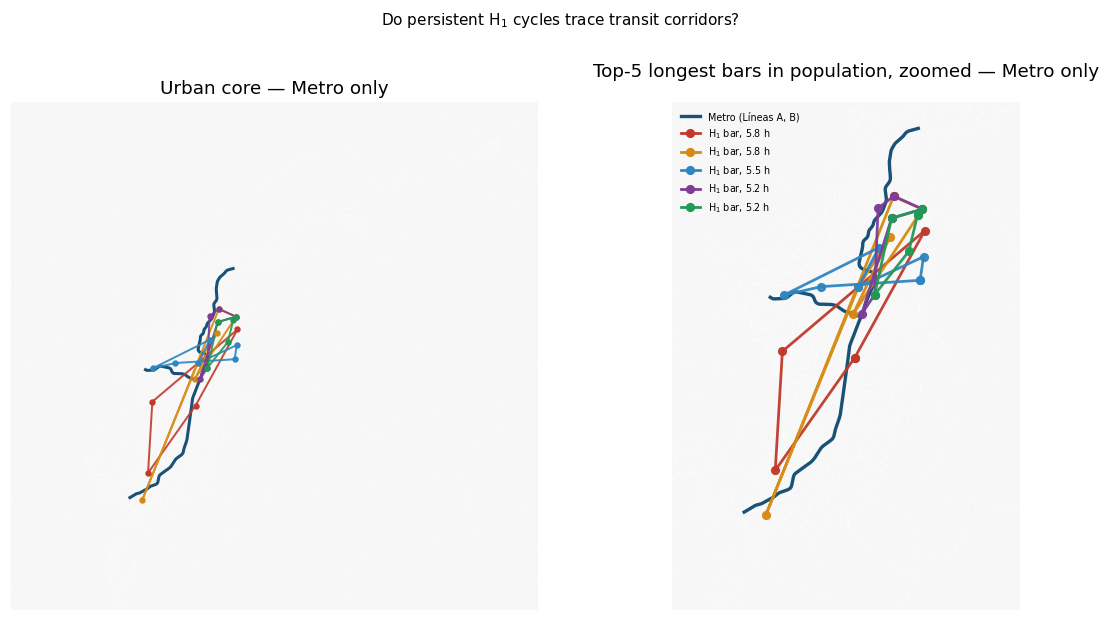

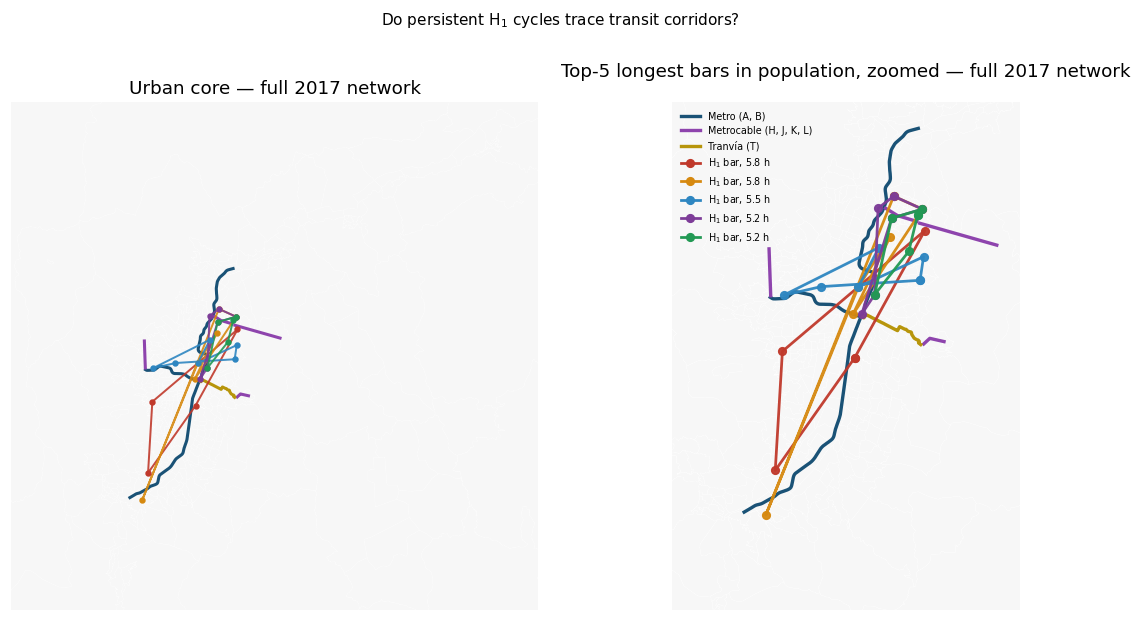

In [19]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from shapely.geometry import LineString

def cycle_geom(cyc):
    pts = [cent[z] for z in cyc if z in cent.index]
    if len(pts) < 3:
        return None
    xs = [p.x for p in pts] + [pts[0].x]
    ys = [p.y for p in pts] + [pts[0].y]
    return LineString(list(zip(xs, ys)))

seen_ranks, picked = set(), []
for r in all_cycles:
    if r["bar_rank"] in seen_ranks:
        continue
    seen_ranks.add(r["bar_rank"])
    picked.append(r)
    if len(picked) >= TOP_K_SHOWN:
        break

cycle_colors = ["#C0392B", "#D68910", "#2E86C1", "#7D3C98", "#229954"]
urban = zones[zones.geometry.area < zones.geometry.area.quantile(.75)]
ux0, uy0, ux1, uy1 = urban.total_bounds
upad = 0.08 * max(ux1 - ux0, uy1 - uy0)
zone_bg = "#F7F7F7"

def build_overlay_fig(transit_layers, title_suffix, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11.0, 5.6))
    ax = axes[0]
    zones.plot(ax=ax, color=zone_bg, edgecolor="white", linewidth=.15)
    for gdf_, _, color in transit_layers:
        gdf_.plot(ax=ax, color=color, linewidth=2.0, zorder=5)
    for p, c in zip(picked, cycle_colors):
        g = cycle_geom(p["cycle"])
        if g is None:
            continue
        xs, ys = g.xy
        ax.plot(xs, ys, "-", color=c, lw=1.3, alpha=.9, zorder=6)
        ax.scatter(xs[:-1], ys[:-1], s=10, color=c, zorder=7)
    ax.set_xlim(ux0 - upad, ux1 + upad)
    ax.set_ylim(uy0 - upad, uy1 + upad)
    ax.set_axis_off()
    ax.set_title(f"Urban core{title_suffix}")

    ax = axes[1]
    zone_ids = sorted({z for p in picked for z in p["cycle"]})
    sub = zones[zones.SIT_2017.isin(zone_ids)]
    bx0, by0, bx1, by1 = sub.total_bounds
    pad = 0.25 * max(bx1 - bx0, by1 - by0, 1)
    zones.plot(ax=ax, color=zone_bg, edgecolor="white", linewidth=.2)
    for gdf_, label, color in transit_layers:
        gdf_.plot(ax=ax, color=color, linewidth=2.2, zorder=5, label=label)
    for p, c in zip(picked, cycle_colors):
        g = cycle_geom(p["cycle"])
        if g is None:
            continue
        xs, ys = g.xy
        ax.plot(xs, ys, "-", color=c, lw=1.8, marker="o", ms=5, alpha=.95, zorder=6)
    ax.set_xlim(bx0 - pad, bx1 + pad)
    ax.set_ylim(by0 - pad, by1 + pad)
    ax.set_axis_off()
    ax.set_title(f"Top-{TOP_K_SHOWN} longest bars in population, zoomed{title_suffix}")

    transit_handles = [mpl.lines.Line2D([0], [0], color=color, lw=2.2, label=label)
                        for _, label, color in transit_layers]
    cycle_handles = [mpl.lines.Line2D([0], [0], color=c, lw=1.8, marker="o", ms=5,
                                        label=f"H$_1$ bar, {p['persistence_h']:.1f} h")
                      for p, c in zip(picked, cycle_colors)]
    ax.legend(handles=transit_handles + cycle_handles, loc="upper left", frameon=False, fontsize=6.3)

    fig.suptitle("Do persistent H$_1$ cycles trace transit corridors?", fontsize=10, y=1.00)
    fig.tight_layout()
    fig.savefig(fname, dpi=200, bbox_inches="tight")
    return fig

fig_metro = build_overlay_fig([(metro_only, "Metro (Líneas A, B)", "#1A5276")],
                               " — Metro only", OUT_DIR / "fig_metro_overlay_metro.png")
fig_all = build_overlay_fig(
    [(metro_only, "Metro (A, B)", "#1A5276"),
     (metrocable, "Metrocable (H, J, K, L)", "#8E44AD"),
     (tranvia, "Tranvía (T)", "#B7950B")],
    " — full 2017 network", OUT_DIR / "fig_metro_overlay_full.png")
plt.show()

## 9. Save results

In [21]:
import json

cycles_df.to_csv(OUT_DIR / "metro_overlay_cycle_distances.csv", index=False)

results = {
    "barcode_csv": str(BARCODE_CSV),
    "n_extra_short_lived": int(N_EXTRA_SHORT_LIVED),
    "long_lived_h_min": float(LONG_LIVED_H_MIN),
    "n_bars_in_population": int(len(population)),
    "n_cycles_examined": int(len(cycles_df)),
    "frac_cycles_closer_to_metro_than_null_median": float((cycles_df.pct_metro < 0.5).mean()),
    "frac_cycles_closer_to_any_transit_than_null_median": float((cycles_df.pct_all < 0.5).mean()),
    "mean_percentile_rank_metro": float(cycles_df.pct_metro.mean()),
    "mean_percentile_rank_all_transit": float(cycles_df.pct_all.mean()),
    "permutation_test": permutation_result,
}
with open(OUT_DIR / "metro_overlay_results.json", "w") as f:
    json.dump(results, f, indent=1, ensure_ascii=False)
print(json.dumps(results, indent=1))

{
 "barcode_csv": "outputs/zigzag_bars.csv",
 "n_extra_short_lived": 15,
 "long_lived_h_min": 4.0,
 "n_bars_in_population": 63,
 "n_cycles_examined": 121,
 "frac_cycles_closer_to_metro_than_null_median": 0.8842975206611571,
 "frac_cycles_closer_to_any_transit_than_null_median": 0.8842975206611571,
 "mean_percentile_rank_metro": 0.20409641873278234,
 "mean_percentile_rank_all_transit": 0.1498595041322314,
 "permutation_test": {
  "n_cycles": 121,
  "n_permute": 2000,
  "observed_mean_dist_metro_m": 1529.5881492540875,
  "null_mean_dist_metro_m": 3389.8049863519427,
  "fold_closer_than_null_metro": 2.2161553670541974,
  "p_value_metro": 0.0004997501249375312,
  "observed_mean_dist_all_transit_m": 1057.9867934559916,
  "null_mean_dist_all_transit_m": 3058.3017119917668,
  "fold_closer_than_null_all_transit": 2.8906804233364762,
  "p_value_all_transit": 0.0004997501249375312
 }
}


## 10. Reading the result

- **`p_value_metro` / `p_value_all_transit`** — the fraction of random same-size
  zone-tuple replicates that land at least as close to transit as the real cycle
  population. Small (e.g. < 0.05) means the observed proximity is unlikely under a
  spatially-random null.
- **`fold_closer_than_null_*`** — how many times closer the real cycles sit,
  on average, than a random same-size zone tuple. 1.0 means no difference.
- **Caveat that does not go away by re-running this notebook**: the null here is
  spatially random, not degree-preserving. A positive result says the loops are
  closer to transit than a random *location* would be — it does not yet rule out
  that transit simply runs through the highest-degree zones, which would produce
  the same result without transit "causing" anything. Closing that gap needs the
  same rewire null `null_models.py` runs on barcode structure, generalized to test
  cycle identity — not implemented here.
- **Re-run with a different `N_EXTRA_SHORT_LIVED`** in §1 to see whether the
  association is specific to the very longest-lived loops or holds across a wider
  population.